# 06 — Flow Matching for Robot Policies

In this notebook, we explore **Flow Matching** as a generative
approach for learning multimodal action distributions.

In previous notebooks, we implemented:
- Deterministic Behavior Cloning and Mixture Density Networks.
- Action Chunking and Conditional Variational Autoencoders.
- Diffusion Policy using DDPM noise prediction and iterative sampling.

Flow Matching provides another way to learn a generative model:
instead of predicting noise, we learn a **continuous velocity field**
that transports samples from a simple distribution to the data distribution.

## Learning objectives

By the end of this notebook, we will:

1. Understand probability paths and linear interpolation.
2. Implement Conditional Flow Matching in PyTorch.
3. Train a neural network to predict a velocity field.
4. Generate samples by integrating an ODE.
5. Compare sampling quality and inference cost with DDPM.
6. Extend Flow Matching to conditional robot actions.
7. Generate action chunks and evaluate closed-loop performance.

## Key question

**How can a neural network learn a continuous velocity field that
transforms Gaussian noise into coherent, multimodal robot actions?**

We start with a bimodal 2D distribution and progressively build
a conditional Flow Matching policy for our PointRobot environment.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

n_samples = 5000

means = torch.tensor([
    [-2.0, 0.0],
    [ 2.0, 0.0],
])

modes = torch.randint(0, 2, (n_samples,))

data = means[modes] + 0.3 * torch.randn(n_samples, 2)

print(data.shape)

torch.Size([5000, 2])


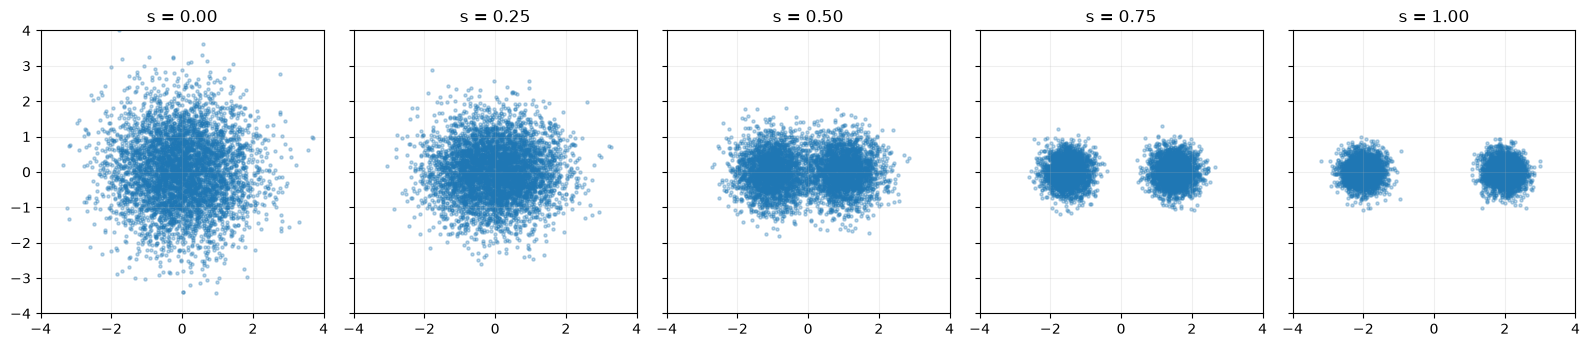

In [3]:
x0 = torch.randn_like(data)
x1 = data

times = [0.0, 0.25, 0.5, 0.75, 1.0]

fig, axes = plt.subplots(
    1, 5,
    figsize=(16, 3.5),
    sharex=True,
    sharey=True,
)

for ax, s in zip(axes, times):

    xs = (1 - s) * x0 + s * x1

    ax.scatter(
        xs[:, 0],
        xs[:, 1],
        s=5,
        alpha=0.3,
    )

    ax.set_title(f"s = {s:.2f}")
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

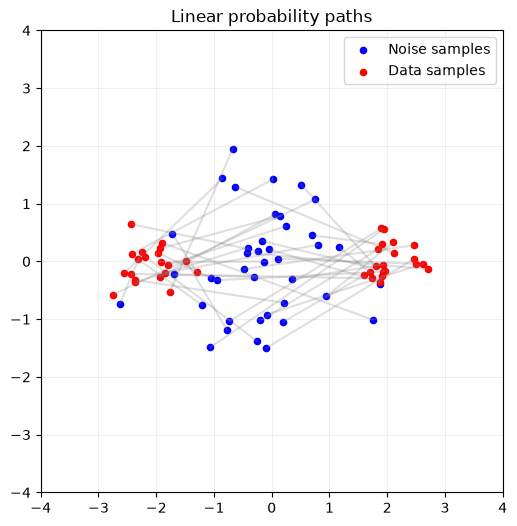

In [4]:
n_plot = 40

fig, ax = plt.subplots(figsize=(7, 6))

for i in range(n_plot):

    start_point = x0[i].numpy()
    end_point = x1[i].numpy()

    ax.plot(
        [start_point[0], end_point[0]],
        [start_point[1], end_point[1]],
        alpha=0.25,
        color="gray",
    )

ax.scatter(
    x0[:n_plot, 0],
    x0[:n_plot, 1],
    color="blue",
    s=20,
    label="Noise samples",
)

ax.scatter(
    x1[:n_plot, 0],
    x1[:n_plot, 1],
    color="red",
    s=20,
    label="Data samples",
)

ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
ax.set_aspect("equal")
ax.set_title("Linear probability paths")
ax.legend()
ax.grid(alpha=0.2)
plt.show()


## Learning the Velocity Field

We now train a neural network to predict the velocity of the
probability flow.

Given two independently sampled points:

- $x_0 \sim \mathcal{N}(0,I)$ from the noise distribution.
- $x_1 \sim p_{\mathrm{data}}$ from the data distribution.

We define a linear interpolation:

$$
x_s = (1-s)x_0 + sx_1
$$

The target velocity along this path is:

$$
u = \frac{dx_s}{ds} = x_1 - x_0
$$

We train a neural network $v_\theta(x_s,s)$ to predict this
velocity using the Flow Matching objective:

$$
\mathcal{L}_{FM} =
\mathbb{E}_{x_0,x_1,s}
\left[
\|v_\theta(x_s,s)-(x_1-x_0)\|^2
\right]
$$

The model learns a time-dependent velocity field that can
transport Gaussian noise toward the data distribution.

After training, we will use this field to generate new samples
by integrating an ordinary differential equation (ODE).

In [5]:
class VelocityField(nn.Module):
    def __init__(self, hidden_dim=128):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(3, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 2),
        )

    def forward(self, x, s):
        # x: (batch_size, 2)
        # s: (batch_size, 1)

        inputs = torch.cat([x, s], dim=-1)

        return self.net(inputs)

In [6]:
velocity_model = VelocityField().to(device)

optimizer = torch.optim.Adam(
    velocity_model.parameters(),
    lr=1e-3,
)

data_train = data.to(device)

n_steps = 5000
batch_size = 256

fm_losses = []

In [7]:
velocity_model.train()

for step_idx in range(n_steps):

    # Sample data points
    indices = torch.randint(
        0,
        len(data_train),
        (batch_size,),
        device=device,
    )

    x1 = data_train[indices]

    # Sample Gaussian noise
    x0 = torch.randn_like(x1)

    # Sample continuous flow time
    s = torch.rand(
        batch_size, 1,
        device=device,
    )

    # Linear interpolation
    xs = (1 - s) * x0 + s * x1

    # Target velocity
    target_velocity = x1 - x0

    # Predicted velocity
    predicted_velocity = velocity_model(xs, s)

    loss = F.mse_loss(
        predicted_velocity,
        target_velocity,
    )

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    fm_losses.append(loss.item())

    if (step_idx + 1) % 500 == 0:
        print(
            f"Step {step_idx + 1}/{n_steps}"
            f" | Loss: {loss.item():.4f}"
        )

Step 500/5000 | Loss: 1.4577
Step 1000/5000 | Loss: 1.2719
Step 1500/5000 | Loss: 1.4671
Step 2000/5000 | Loss: 1.2815
Step 2500/5000 | Loss: 1.4329
Step 3000/5000 | Loss: 1.6118
Step 3500/5000 | Loss: 1.2164
Step 4000/5000 | Loss: 1.5169
Step 4500/5000 | Loss: 1.4108
Step 5000/5000 | Loss: 1.5439


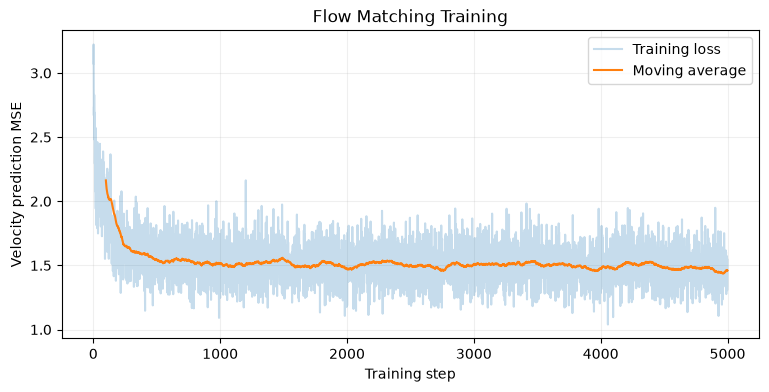

In [8]:
plt.figure(figsize=(9, 4))

plt.plot(
    fm_losses,
    alpha=0.25,
    label="Training loss",
)

window = 100

smoothed = np.convolve(
    fm_losses,
    np.ones(window) / window,
    mode="valid",
)

plt.plot(
    np.arange(window - 1, len(fm_losses)),
    smoothed,
    label="Moving average",
)

plt.xlabel("Training step")
plt.ylabel("Velocity prediction MSE")
plt.title("Flow Matching Training")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [9]:
@torch.no_grad()
def plot_velocity_field(model, s_value, ax):
    model.eval()

    xx, yy = np.meshgrid(
        np.linspace(-4, 4, 23),
        np.linspace(-3, 3, 17),
    )

    points = np.stack(
        [xx.ravel(), yy.ravel()],
        axis=-1,
    )

    x = torch.tensor(
        points,
        dtype=torch.float32,
        device=device,
    )

    s = torch.full(
        (len(x), 1),
        s_value,
        device=device,
    )

    velocity = model(x, s).cpu().numpy()

    vx = velocity[:, 0].reshape(xx.shape)
    vy = velocity[:, 1].reshape(yy.shape)

    ax.quiver(
        xx, yy, vx, vy,
        angles="xy",
        scale_units="xy",
        scale=10,
    )

    ax.scatter(
        [-2, 2],
        [0, 0],
        color="red",
        s=35,
        label="Data modes",
    )

    ax.set_xlim(-4, 4)
    ax.set_ylim(-3, 3)
    ax.set_aspect("equal")
    ax.set_title(f"Velocity field at s={s_value:.2f}")
    ax.grid(alpha=0.2)

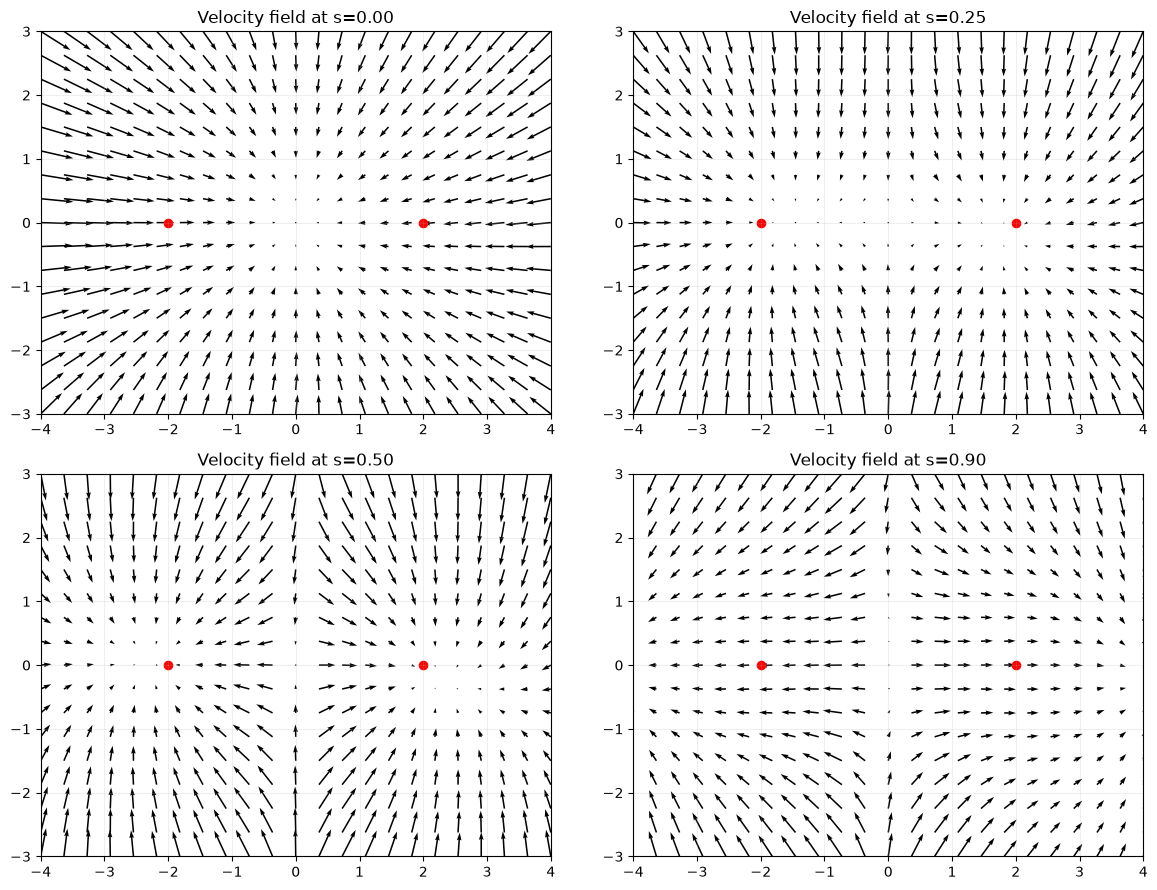

In [10]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 9),
)

for ax, s_value in zip(
    axes.flat,
    [0.0, 0.25, 0.5, 0.9],
):
    plot_velocity_field(
        velocity_model,
        s_value,
        ax,
    )

plt.tight_layout()
plt.show()

## Sampling with ODE Integration

We have trained a neural network to predict a time-dependent
velocity field:

$$
v_\theta(x,s)
$$

We now generate samples by integrating the ordinary differential
equation:

$$
\frac{dx}{ds}=v_\theta(x,s)
$$

Starting from Gaussian noise:

$$
x(0)\sim\mathcal{N}(0,I)
$$

we integrate from $s=0$ to $s=1$.

We initially use the explicit Euler method:

$$
x_{i+1}=x_i+\Delta s\,v_\theta(x_i,s_i)
$$

where $\Delta s=1/N$ and $N$ is the number of integration steps.

Each Euler step requires one neural network evaluation.

We will investigate how the number of integration steps affects
sample quality and computational cost.

In [11]:
@torch.no_grad()
def flow_sample(
    model,
    n_samples=2000,
    n_steps=50,
    return_history=False,
):
    model.eval()

    # Initial Gaussian noise
    x = torch.randn(
        n_samples,
        2,
        device=device,
    )

    dt = 1.0 / n_steps

    history = [x.cpu().clone()]

    for i in range(n_steps):

        s = i * dt

        s_batch = torch.full(
            (n_samples, 1),
            s,
            device=device,
        )

        # Predict velocity
        velocity = model(x, s_batch)

        # Euler integration
        x = x + dt * velocity

        if return_history:
            history.append(x.cpu().clone())

    if return_history:
        return x.cpu(), history

    return x.cpu()

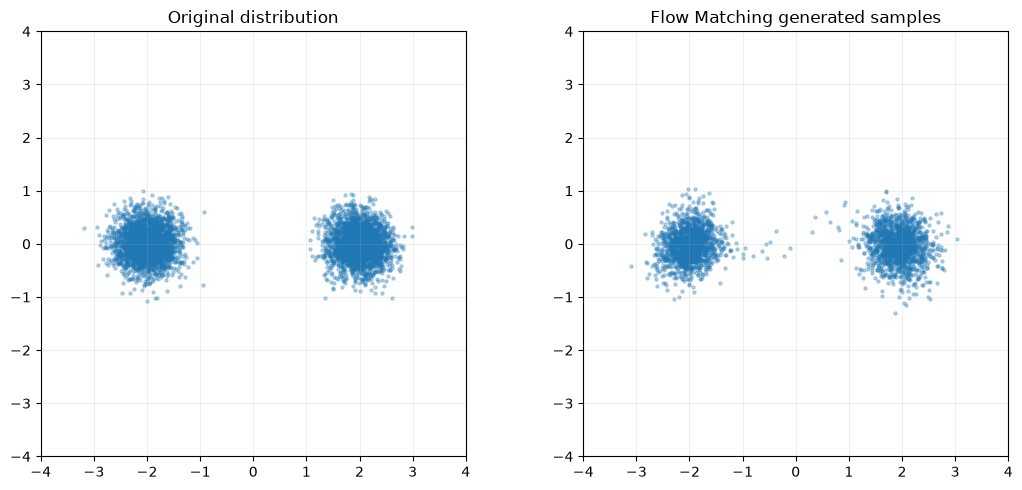

In [12]:
generated = flow_sample(
    velocity_model,
    n_samples=3000,
    n_steps=50,
)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].scatter(
    data[:, 0],
    data[:, 1],
    s=5,
    alpha=0.3,
)
axes[0].set_title("Original distribution")

axes[1].scatter(
    generated[:, 0],
    generated[:, 1],
    s=5,
    alpha=0.3,
)
axes[1].set_title("Flow Matching generated samples")

for ax in axes:
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

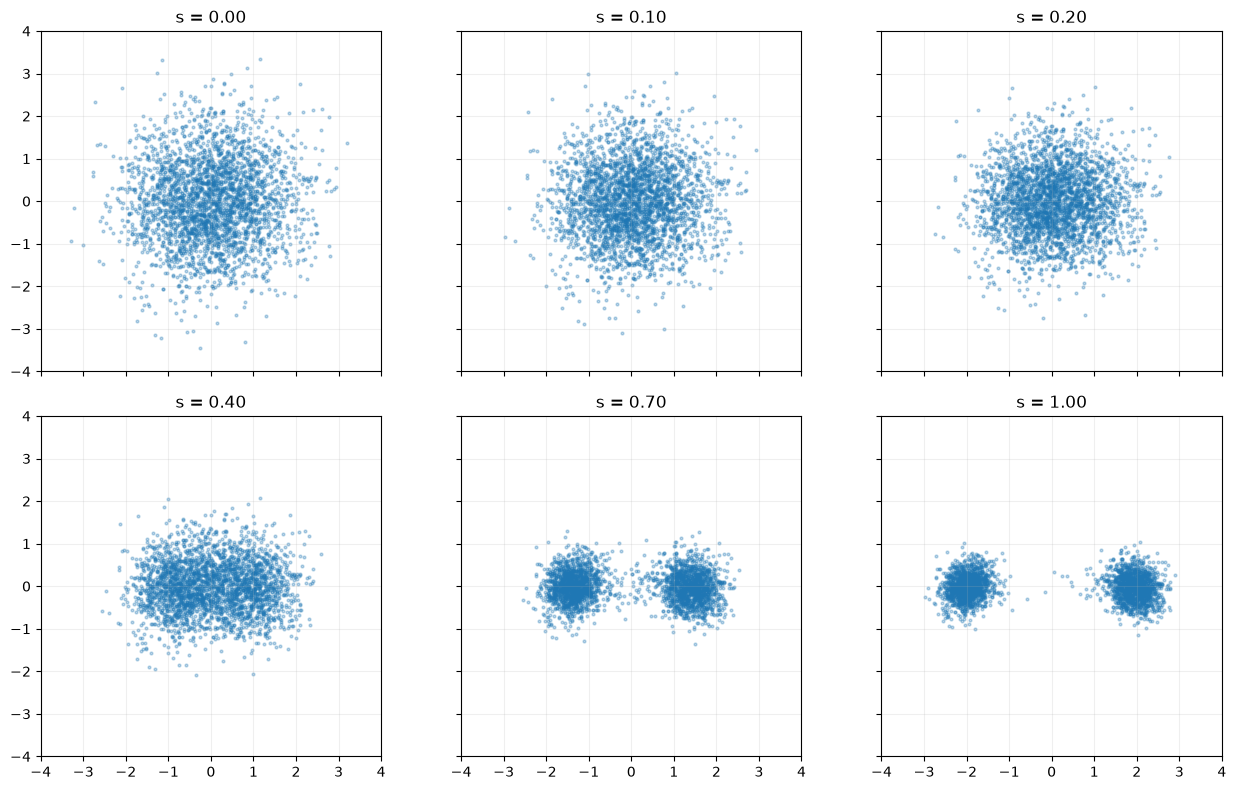

In [13]:
generated, history = flow_sample(
    velocity_model,
    n_samples=3000,
    n_steps=50,
    return_history=True,
)

steps_to_plot = [0, 5, 10, 20, 35, 50]

fig, axes = plt.subplots(
    2, 3,
    figsize=(13, 8),
    sharex=True,
    sharey=True,
)

for ax, i in zip(axes.flat, steps_to_plot):

    samples = history[i]

    ax.scatter(
        samples[:, 0],
        samples[:, 1],
        s=4,
        alpha=0.3,
    )

    ax.set_title(f"s = {i / 50:.2f}")

    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Sampling Quality vs Integration Steps

Flow Matching generates samples by numerically integrating
a learned velocity field.

The number of integration steps controls the trade-off between
sampling accuracy and computational cost.

We compare Euler integration using:

- 5 steps
- 10 steps
- 20 steps
- 50 steps
- 100 steps

All configurations use the same trained velocity model.

A smaller number of steps requires fewer neural network evaluations,
but may introduce larger numerical integration errors.

We investigate whether the generated bimodal distribution
remains accurate with fewer steps.

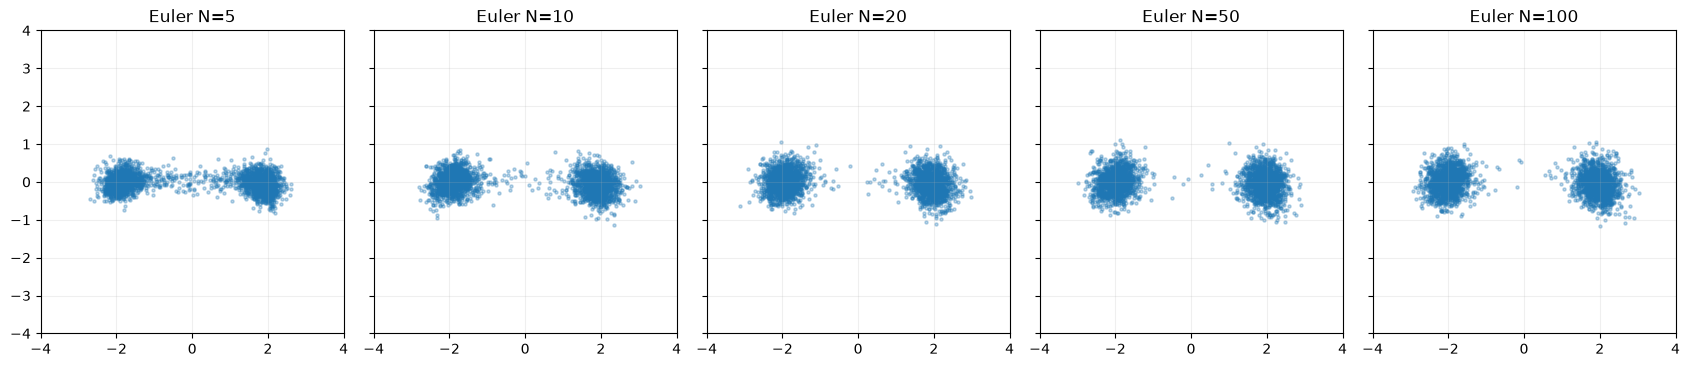

In [15]:
integration_steps = [5, 10, 20, 50, 100]

fig, axes = plt.subplots(
    1, 5,
    figsize=(17, 3.5),
    sharex=True,
    sharey=True,
)

for ax, n_steps in zip(axes, integration_steps):

    samples = flow_sample(
        velocity_model,
        n_samples=3000,
        n_steps=n_steps,
    )

    ax.scatter(
        samples[:, 0],
        samples[:, 1],
        s=5,
        alpha=0.3,
    )

    ax.set_title(f"Euler N={n_steps}")
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Conditional Flow Matching for Robot Actions

We now extend Flow Matching to learn a robot policy.

Our dataset contains expert demonstrations represented as
observation-action pairs:

$$
\mathcal{D}=\{(o_t,a_t)\}
$$

Instead of learning an unconditional distribution $p(a)$,
we want to learn a conditional action distribution:

$$
\pi_\theta(a_t\mid o_t)
$$

We train a velocity field conditioned on the robot observation:

$$
v_\theta(a_s,s,o_t)
$$

For each expert action $a_1$, we sample Gaussian noise
$a_0 \sim \mathcal{N}(0,I)$ and interpolate:

$$
a_s=(1-s)a_0+sa_1
$$

The target velocity is:

$$
u=a_1-a_0
$$

The Conditional Flow Matching objective is:

$$
\mathcal{L}_{CFM}=
\mathbb{E}
\left[
\|v_\theta(a_s,s,o_t)-(a_1-a_0)\|^2
\right]
$$

At inference time, we start from Gaussian noise and integrate
the learned velocity field while keeping the robot observation fixed.

This produces a stochastic action policy capable of representing
multiple valid behaviors for the same observation.

In [19]:
from robot_learning_playground.point_robot import collect_demonstrations, step
from torch.utils.data import TensorDataset, DataLoader

# Reuse the expert demonstration dataset from previous notebooks.
# Each observation must be paired with its expert action.

demonstrations = collect_demonstrations(
    n_episodes=500,
    seed=42,
)

observations = np.concatenate([
    demo["observations"]
    for demo in demonstrations
])

actions = np.concatenate([
    demo["actions"]
    for demo in demonstrations
])

observations = torch.as_tensor(
    observations,
    dtype=torch.float32,
)

actions = torch.as_tensor(
    actions,
    dtype=torch.float32,
)

assert observations.ndim == 2
assert actions.ndim == 2
assert actions.shape[1] == 2
assert len(observations) == len(actions)

obs_dim = observations.shape[1]
action_dim = actions.shape[1]

print("Observations:", observations.shape)
print("Actions:", actions.shape)

Observations: torch.Size([12768, 4])
Actions: torch.Size([12768, 2])


In [20]:
action_mean = actions.mean(dim=0)
action_std = actions.std(dim=0).clamp_min(1e-6)

normalized_actions = (
    actions - action_mean
) / action_std

print("Action mean:", action_mean)
print("Action std:", action_std)

Action mean: tensor([-1.7981e-05,  3.9160e-02])
Action std: tensor([0.0280, 0.0068])


In [ ]:
# Input: (action, s, observation)
# Output: (velocity)

class ConditionalVelocityField(nn.Module):
    def __init__(
        self,
        obs_dim,
        action_dim=2,
        hidden_dim=128,
    ):
        super().__init__()

        input_dim = action_dim + 1 + obs_dim

        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, action_dim),
        )

    def forward(self, action, s, observation):
        x = torch.cat(
            [action, s, observation],
            dim=-1,
        )

        return self.net(x)

In [22]:
conditional_flow = ConditionalVelocityField(
    obs_dim=obs_dim,
    action_dim=action_dim,
).to(device)

optimizer = torch.optim.Adam(
    conditional_flow.parameters(),
    lr=1e-3,
)

obs_train = observations.to(device)
actions_train = normalized_actions.to(device)

n_steps = 5000
batch_size = 256

conditional_losses = []

conditional_flow.train()

for step_idx in range(n_steps):

    indices = torch.randint(
        0,
        len(obs_train),
        (batch_size,),
        device=device,
    )

    obs = obs_train[indices]
    a1 = actions_train[indices]

    # Initial Gaussian noise
    a0 = torch.randn_like(a1)

    # Continuous flow time
    s = torch.rand(
        batch_size, 1,
        device=device,
    )

    # Linear interpolation
    a_s = (1 - s) * a0 + s * a1

    # Target velocity
    target_velocity = a1 - a0

    # Predicted velocity
    predicted_velocity = conditional_flow(
        a_s,
        s,
        obs,
    )

    loss = F.mse_loss(
        predicted_velocity,
        target_velocity,
    )

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    conditional_losses.append(loss.item())

    if (step_idx + 1) % 500 == 0:
        print(
            f"Step {step_idx + 1}/{n_steps} "
            f"| Loss: {loss.item():.4f}"
        )

Step 500/5000 | Loss: 1.1056
Step 1000/5000 | Loss: 0.7783
Step 1500/5000 | Loss: 0.7736
Step 2000/5000 | Loss: 0.9443
Step 2500/5000 | Loss: 0.6035
Step 3000/5000 | Loss: 0.4978
Step 3500/5000 | Loss: 0.5564
Step 4000/5000 | Loss: 0.3581
Step 4500/5000 | Loss: 0.4396
Step 5000/5000 | Loss: 0.3433


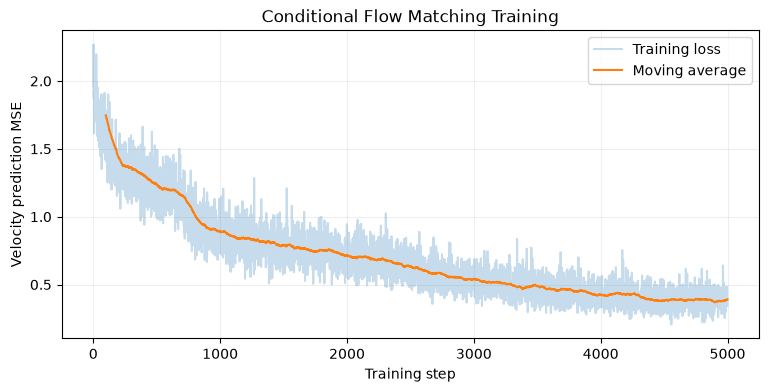

In [23]:
plt.figure(figsize=(9, 4))

plt.plot(
    conditional_losses,
    alpha=0.25,
    label="Training loss",
)

window = 100

smoothed = np.convolve(
    conditional_losses,
    np.ones(window) / window,
    mode="valid",
)

plt.plot(
    np.arange(window - 1, len(conditional_losses)),
    smoothed,
    label="Moving average",
)

plt.xlabel("Training step")
plt.ylabel("Velocity prediction MSE")
plt.title("Conditional Flow Matching Training")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [24]:
@torch.no_grad()
def conditional_flow_sample(
    model,
    observation,
    n_samples=1000,
    n_steps=20,
):
    model.eval()

    obs = torch.as_tensor(
        observation,
        dtype=torch.float32,
        device=device,
    ).reshape(1, -1)

    obs = obs.expand(n_samples, -1)

    # Initial noise in normalized action space
    a = torch.randn(
        n_samples,
        action_dim,
        device=device,
    )

    dt = 1.0 / n_steps

    for i in range(n_steps):

        s = torch.full(
            (n_samples, 1),
            i * dt,
            device=device,
        )

        velocity = model(a, s, obs)

        a = a + dt * velocity

    # Denormalize actions
    mean = action_mean.to(device)
    std = action_std.to(device)

    actions = a * std + mean

    return actions.cpu()

In [26]:
from robot_learning_playground.point_robot import make_observation

start = np.array([0.0, 0.0])
goal = np.array([0.0, 1.0])

initial_observation = make_observation(
    start,
    goal,
)

generated_actions = conditional_flow_sample(
    conditional_flow,
    initial_observation,
    n_samples=2000,
    n_steps=20,
).numpy()

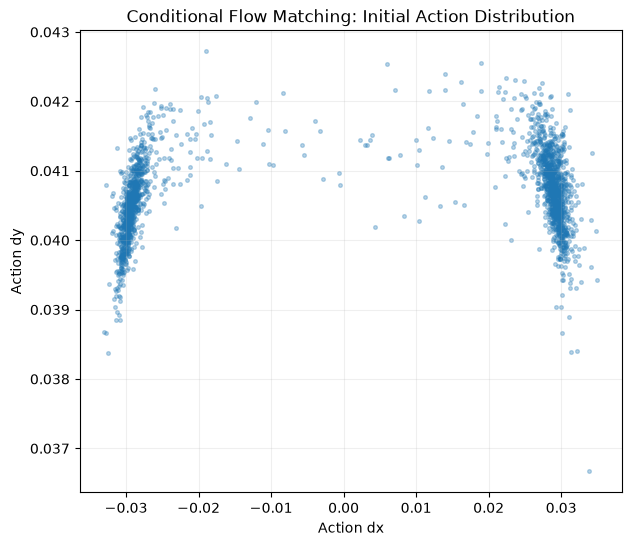

In [27]:
plt.figure(figsize=(7, 6))

plt.scatter(
    generated_actions[:, 0],
    generated_actions[:, 1],
    s=7,
    alpha=0.3,
)

plt.xlabel("Action dx")
plt.ylabel("Action dy")
plt.title("Conditional Flow Matching: Initial Action Distribution")
plt.grid(alpha=0.2)
plt.show()

## Closed-loop Evaluation: Single-Action Flow Matching

We have verified that Conditional Flow Matching learns a multimodal
action distribution at the initial robot observation.

We now evaluate the learned policy in closed-loop.

At each robot timestep:

1. Observe the current robot state.
2. Sample Gaussian noise in normalized action space.
3. Integrate the conditional velocity field from s=0 to s=1.
4. Execute the generated action.
5. Repeat until success, collision, or timeout.

We evaluate success rate, collision rate, and timeout rate.

This experiment investigates whether a learned multimodal
single-action distribution produces coherent robot behavior.

In [29]:
from robot_learning_playground.point_robot import is_collision

def rollout_conditional_flow(
    start,
    goal,
    n_flow_steps=20,
    max_steps=100,
    goal_tolerance=0.05,
):
    position = np.asarray(start, dtype=float).copy()
    goal = np.asarray(goal, dtype=float)

    positions = [position.copy()]
    actions = []

    success = False
    collision = False

    for _ in range(max_steps):

        observation = make_observation(position, goal)

        action = conditional_flow_sample(
            conditional_flow,
            observation,
            n_samples=1,
            n_steps=n_flow_steps,
        )[0].numpy()

        position = np.asarray(
            step(position, action),
            dtype=float,
        ).copy()

        positions.append(position.copy())
        actions.append(action.copy())

        if is_collision(position):
            collision = True
            break

        if np.linalg.norm(position - goal) < goal_tolerance:
            success = True
            break

    return {
        "positions": np.asarray(positions),
        "actions": np.asarray(actions),
        "success": success,
        "collision": collision,
    }

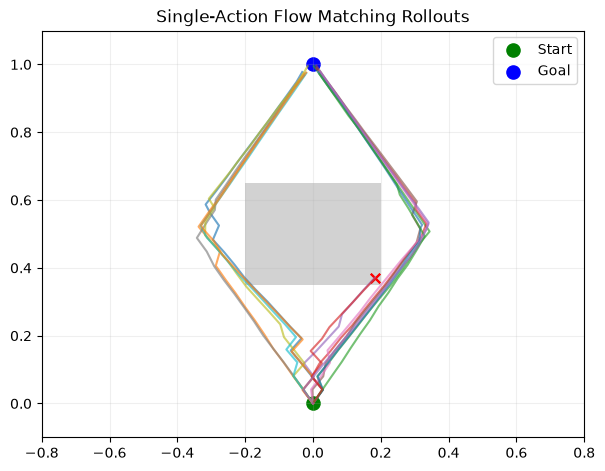

In [30]:
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(7, 7))

ax.add_patch(
    Rectangle(
        (-0.2, 0.35),
        0.4,
        0.3,
        facecolor="gray",
        alpha=0.35,
    )
)

for _ in range(15):
    r = rollout_conditional_flow(start, goal)

    positions = r["positions"]

    ax.plot(
        positions[:, 0],
        positions[:, 1],
        alpha=0.65,
    )

    if r["collision"]:
        ax.scatter(
            *positions[-1],
            color="red",
            marker="x",
            s=45,
        )

ax.scatter(*start, color="green", s=90, label="Start")
ax.scatter(*goal, color="blue", s=90, label="Goal")

ax.set_xlim(-0.8, 0.8)
ax.set_ylim(-0.1, 1.1)
ax.set_aspect("equal")
ax.set_title("Single-Action Flow Matching Rollouts")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

In [31]:
n_eval = 100

rollouts = [
    rollout_conditional_flow(start, goal)
    for _ in range(n_eval)
]

success_rate = np.mean([r["success"] for r in rollouts])
collision_rate = np.mean([r["collision"] for r in rollouts])

timeout_rate = np.mean([
    not r["success"] and not r["collision"]
    for r in rollouts
])

print(f"Success rate:   {success_rate:.1%}")
print(f"Collision rate: {collision_rate:.1%}")
print(f"Timeout rate:   {timeout_rate:.1%}")

Success rate:   81.0%
Collision rate: 19.0%
Timeout rate:   0.0%


## Chunk Flow Matching

Single-action Conditional Flow Matching achieved promising closed-loop
performance, but it generates each action independently from fresh noise.

We now extend the model to generate complete action chunks.

The policy models:

$$
\pi_\theta(A_{t:t+H-1}\mid o_t)
$$

where $H=8$ is the action prediction horizon.

We train a conditional velocity field:

$$
v_\theta(A_s,s,o_t)
$$

where $A_s$ is a noisy/interpolated action chunk.

Given a demonstration chunk $A_1$ and Gaussian noise $A_0$:

$$
A_s=(1-s)A_0+sA_1
$$

The target velocity is:

$$
U=A_1-A_0
$$

The Flow Matching objective becomes:

$$
\mathcal{L}_{CFM}=
\mathbb{E}\left[
\|v_\theta(A_s,s,o_t)-(A_1-A_0)\|^2
\right]
$$

At inference time, we integrate the velocity field from $s=0$ to
$s=1$ to generate a complete action chunk.

We will investigate whether chunk generation improves temporal
coherence and closed-loop performance.

In [32]:
H = 8

chunk_observations = []
chunk_actions = []

for episode in demonstrations:
    obs = np.asarray(episode["observations"])
    acts = np.asarray(episode["actions"])

    for t in range(len(acts) - H + 1):
        chunk_observations.append(obs[t])
        chunk_actions.append(acts[t:t + H])

chunk_observations = torch.as_tensor(
    np.asarray(chunk_observations),
    dtype=torch.float32,
)

chunk_actions = torch.as_tensor(
    np.asarray(chunk_actions),
    dtype=torch.float32,
)

print("Observations:", chunk_observations.shape)
print("Action chunks:", chunk_actions.shape)

Observations: torch.Size([9268, 4])
Action chunks: torch.Size([9268, 8, 2])


In [33]:
normalized_chunks = (
    chunk_actions - action_mean.view(1, 1, -1)
) / action_std.view(1, 1, -1)

In [34]:
class ChunkVelocityField(nn.Module):
    def __init__(
        self,
        obs_dim,
        action_dim=2,
        horizon=8,
        hidden_dim=256,
    ):
        super().__init__()

        self.horizon = horizon
        self.action_dim = action_dim

        chunk_dim = horizon * action_dim
        input_dim = chunk_dim + 1 + obs_dim

        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, chunk_dim),
        )

    def forward(self, chunk, s, observation):
        batch_size = chunk.shape[0]

        flat_chunk = chunk.reshape(batch_size, -1)

        x = torch.cat(
            [flat_chunk, s, observation],
            dim=-1,
        )

        velocity = self.net(x)

        return velocity.reshape(
            batch_size,
            self.horizon,
            self.action_dim,
        )

In [35]:
chunk_flow = ChunkVelocityField(
    obs_dim=obs_dim,
    action_dim=action_dim,
    horizon=H,
).to(device)

optimizer = torch.optim.Adam(
    chunk_flow.parameters(),
    lr=1e-3,
)

chunk_obs_train = chunk_observations.to(device)
chunk_actions_train = normalized_chunks.to(device)

n_steps = 5000
batch_size = 256

chunk_losses = []

chunk_flow.train()

for step_idx in range(n_steps):

    indices = torch.randint(
        0,
        len(chunk_obs_train),
        (batch_size,),
        device=device,
    )

    obs = chunk_obs_train[indices]
    A1 = chunk_actions_train[indices]

    # Gaussian noise over the entire chunk
    A0 = torch.randn_like(A1)

    s = torch.rand(
        batch_size, 1,
        device=device,
    )

    # Broadcast flow time across chunk dimensions
    s_chunk = s.unsqueeze(-1)

    A_s = (1 - s_chunk) * A0 + s_chunk * A1

    target_velocity = A1 - A0

    predicted_velocity = chunk_flow(
        A_s,
        s,
        obs,
    )

    loss = F.mse_loss(
        predicted_velocity,
        target_velocity,
    )

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    chunk_losses.append(loss.item())

    if (step_idx + 1) % 500 == 0:
        print(
            f"Step {step_idx + 1}/{n_steps} "
            f"| Loss: {loss.item():.4f}"
        )

Step 500/5000 | Loss: 0.8007
Step 1000/5000 | Loss: 0.5946
Step 1500/5000 | Loss: 0.4650
Step 2000/5000 | Loss: 0.4213
Step 2500/5000 | Loss: 0.3525
Step 3000/5000 | Loss: 0.3596
Step 3500/5000 | Loss: 0.3139
Step 4000/5000 | Loss: 0.2701
Step 4500/5000 | Loss: 0.3216
Step 5000/5000 | Loss: 0.2702


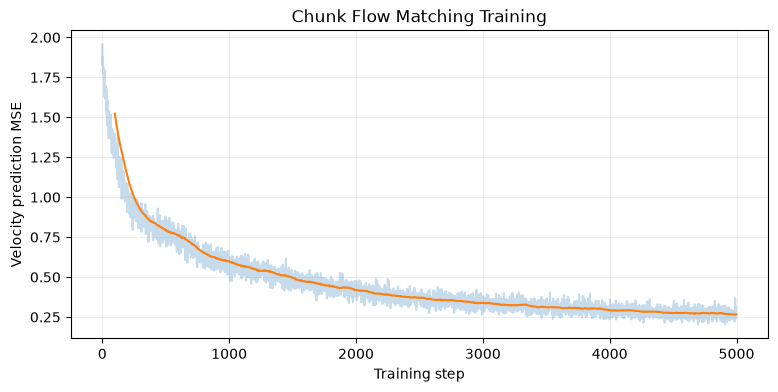

In [36]:
plt.figure(figsize=(9, 4))

plt.plot(chunk_losses, alpha=0.25)

window = 100

smoothed = np.convolve(
    chunk_losses,
    np.ones(window) / window,
    mode="valid",
)

plt.plot(
    np.arange(window - 1, len(chunk_losses)),
    smoothed,
)

plt.xlabel("Training step")
plt.ylabel("Velocity prediction MSE")
plt.title("Chunk Flow Matching Training")
plt.grid(alpha=0.2)
plt.show()

In [37]:
@torch.no_grad()
def chunk_flow_sample(
    model,
    observation,
    n_samples=100,
    n_steps=20,
):
    model.eval()

    obs = torch.as_tensor(
        observation,
        dtype=torch.float32,
        device=device,
    ).reshape(1, -1)

    obs = obs.expand(n_samples, -1)

    # Initial Gaussian noise over the complete chunk
    A = torch.randn(
        n_samples,
        H,
        action_dim,
        device=device,
    )

    dt = 1.0 / n_steps

    for i in range(n_steps):

        s = torch.full(
            (n_samples, 1),
            i * dt,
            device=device,
        )

        velocity = model(A, s, obs)

        A = A + dt * velocity

    # Denormalize the generated chunks
    mean = action_mean.to(device).view(1, 1, -1)
    std = action_std.to(device).view(1, 1, -1)

    chunks = A * std + mean

    return chunks.cpu()

In [38]:
generated_chunks = chunk_flow_sample(
    chunk_flow,
    initial_observation,
    n_samples=1000,
    n_steps=20,
)

print(generated_chunks.shape)

torch.Size([1000, 8, 2])


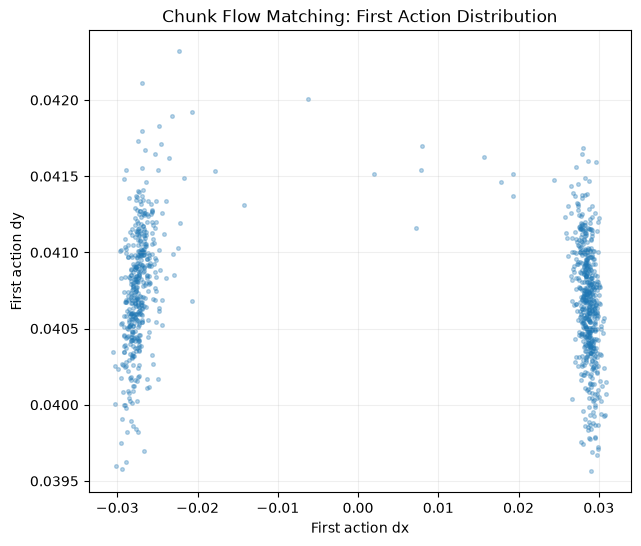

In [39]:
first_actions = generated_chunks[:, 0, :].numpy()

plt.figure(figsize=(7, 6))

plt.scatter(
    first_actions[:, 0],
    first_actions[:, 1],
    s=7,
    alpha=0.3,
)

plt.xlabel("First action dx")
plt.ylabel("First action dy")
plt.title("Chunk Flow Matching: First Action Distribution")
plt.grid(alpha=0.2)
plt.show()

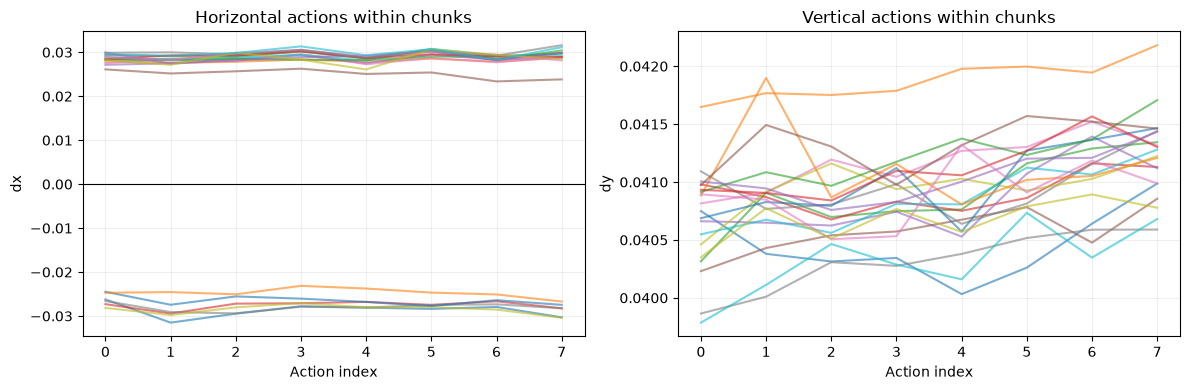

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i in range(20):
    chunk = generated_chunks[i].numpy()

    axes[0].plot(chunk[:, 0], alpha=0.6)
    axes[1].plot(chunk[:, 1], alpha=0.6)

axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Horizontal actions within chunks")
axes[0].set_ylabel("dx")

axes[1].set_title("Vertical actions within chunks")
axes[1].set_ylabel("dy")

for ax in axes:
    ax.set_xlabel("Action index")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Closed-loop Evaluation of Chunk Flow Matching

We have verified that Chunk Flow Matching generates multimodal,
temporally coherent action sequences.

We now evaluate the learned policy in closed-loop.

The prediction horizon is fixed at $H=8$.

We compare execution horizons:

$$
E \in \{1,2,4,8\}
$$

At each replanning step, the policy generates a complete action chunk
by integrating the conditional velocity field.

Only the first $E$ actions are executed before observing the robot
and generating a new chunk.

We measure:

- Success rate.
- Collision rate.
- Timeout rate.
- Number of policy calls per episode.

We investigate the trade-off between temporal coherence,
closed-loop feedback, and inference cost.

In [42]:
def rollout_chunk_flow(
    start,
    goal,
    execution_horizon=2,
    n_flow_steps=20,
    max_steps=100,
    goal_tolerance=0.05,
):
    assert 1 <= execution_horizon <= H

    position = np.asarray(start, dtype=float).copy()
    goal = np.asarray(goal, dtype=float)

    positions = [position.copy()]
    actions = []

    success = False
    collision = False
    policy_calls = 0

    while len(actions) < max_steps:

        observation = make_observation(position, goal)

        chunk = chunk_flow_sample(
            chunk_flow,
            observation,
            n_samples=1,
            n_steps=n_flow_steps,
        )[0].numpy()

        policy_calls += 1

        for action in chunk[:execution_horizon]:

            if len(actions) >= max_steps:
                break

            position = np.asarray(
                step(position, action),
                dtype=float,
            ).copy()

            positions.append(position.copy())
            actions.append(action.copy())

            if is_collision(position):
                collision = True
                break

            if np.linalg.norm(position - goal) < goal_tolerance:
                success = True
                break

        if success or collision:
            break

    return {
        "positions": np.asarray(positions),
        "actions": np.asarray(actions),
        "success": success,
        "collision": collision,
        "policy_calls": policy_calls,
    }

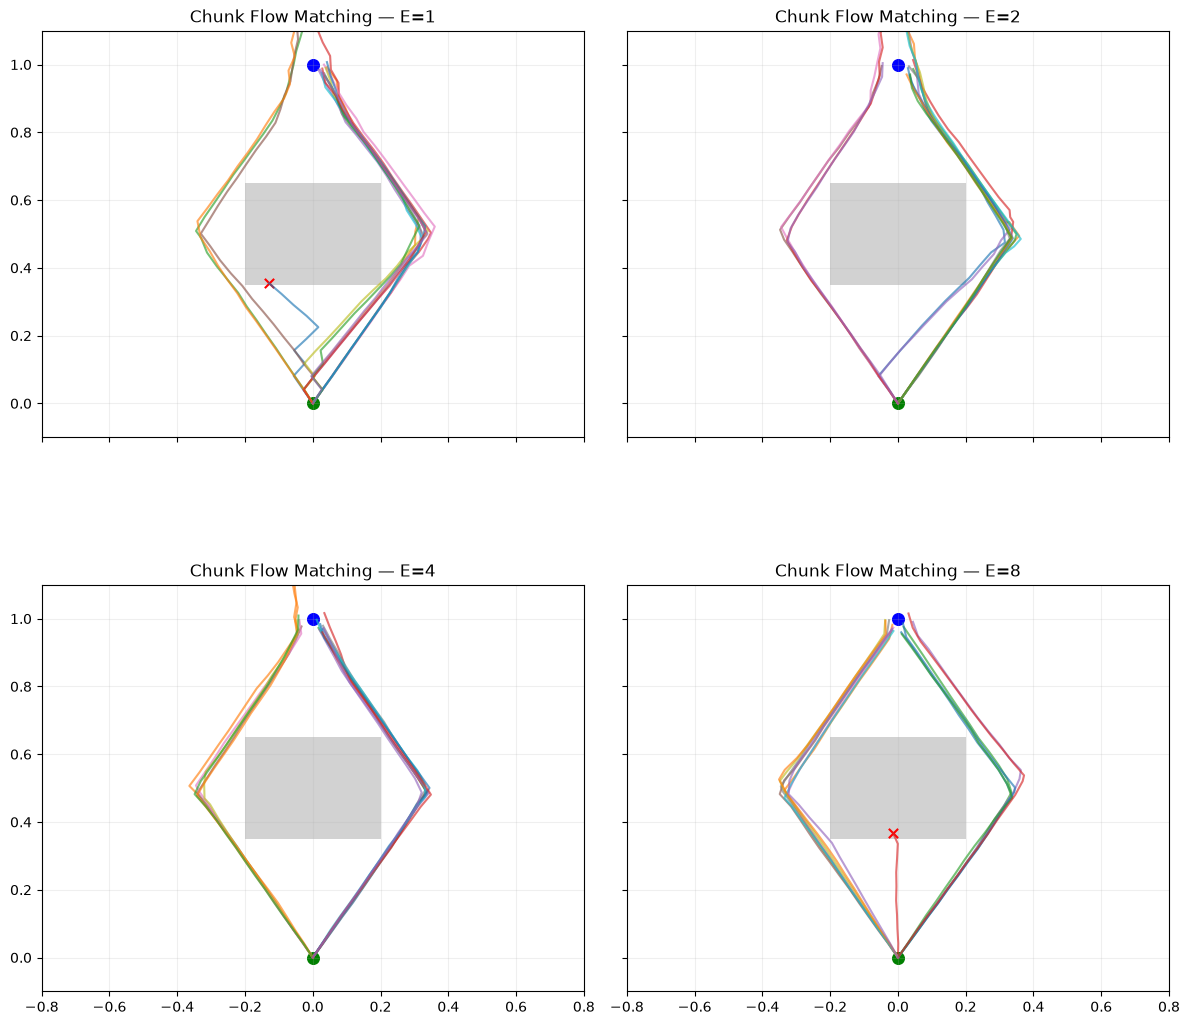

In [43]:
from matplotlib.patches import Rectangle

execution_horizons = [1, 2, 4, 8]

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 12),
    sharex=True,
    sharey=True,
)

for ax, E in zip(axes.flat, execution_horizons):

    ax.add_patch(
        Rectangle(
            (-0.2, 0.35),
            0.4,
            0.3,
            facecolor="gray",
            alpha=0.35,
        )
    )

    for _ in range(15):

        rollout = rollout_chunk_flow(
            start,
            goal,
            execution_horizon=E,
        )

        positions = rollout["positions"]

        ax.plot(
            positions[:, 0],
            positions[:, 1],
            alpha=0.65,
        )

        if rollout["collision"]:
            ax.scatter(
                *positions[-1],
                color="red",
                marker="x",
                s=45,
            )

    ax.scatter(*start, color="green", s=70)
    ax.scatter(*goal, color="blue", s=70)

    ax.set_title(f"Chunk Flow Matching — E={E}")
    ax.set_xlim(-0.8, 0.8)
    ax.set_ylim(-0.1, 1.1)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [44]:
n_eval = 100
results = {}

for E in execution_horizons:

    evaluations = [
        rollout_chunk_flow(
            start,
            goal,
            execution_horizon=E,
        )
        for _ in range(n_eval)
    ]

    success_rate = np.mean([
        r["success"] for r in evaluations
    ])

    collision_rate = np.mean([
        r["collision"] for r in evaluations
    ])

    timeout_rate = np.mean([
        not r["success"] and not r["collision"]
        for r in evaluations
    ])

    mean_policy_calls = np.mean([
        r["policy_calls"] for r in evaluations
    ])

    results[E] = {
        "success": success_rate,
        "collision": collision_rate,
        "timeout": timeout_rate,
        "policy_calls": mean_policy_calls,
    }

    print(
        f"E={E} | "
        f"Success: {success_rate:.1%} | "
        f"Collision: {collision_rate:.1%} | "
        f"Timeout: {timeout_rate:.1%} | "
        f"Policy calls: {mean_policy_calls:.1f}"
    )
    

E=1 | Success: 55.0% | Collision: 2.0% | Timeout: 43.0% | Policy calls: 57.2
E=2 | Success: 60.0% | Collision: 5.0% | Timeout: 35.0% | Policy calls: 25.4
E=4 | Success: 82.0% | Collision: 0.0% | Timeout: 18.0% | Policy calls: 9.8
E=8 | Success: 93.0% | Collision: 0.0% | Timeout: 7.0% | Policy calls: 4.2


## Conclusions

In this notebook, we implemented **Flow Matching** from scratch
and progressively extended it into a conditional robot policy.

### Key takeaways

1. **Flow Matching learns a velocity field.**
   Instead of predicting diffusion noise, the network learns a
   time-dependent vector field that transports Gaussian noise
   toward the data distribution.

2. **Generation is performed by ODE integration.**
   Starting from Gaussian noise, we integrate the learned
   velocity field from flow time 0 to 1.

3. **Multimodal distributions emerge from deterministic flows.**
   Different initial noise samples follow different trajectories,
   allowing the model to generate multiple distinct modes.

4. **Few integration steps can be sufficient.**
   In our toy experiments, Euler integration with 20 steps
   generated convincing bimodal distributions.

5. **Conditional Flow Matching produces robot actions.**
   Conditioning the velocity field on observations allows
   us to model a stochastic robot policy.

6. **Chunk Flow Matching captures temporal dependencies.**
   Generating complete action sequences improves coherence
   within each chunk.

7. **Execution horizon strongly affects closed-loop behavior.**
   With H=8 and E=8, our Chunk Flow Matching policy achieved
   93% success and 0% observed collisions over 100 episodes.

### Limitations

Our implementation uses a simple MLP, a fixed PointRobot
environment, and explicit Euler integration.

The experiments do not establish that Flow Matching is
universally faster or more accurate than diffusion models.

The policy is also limited by demonstration coverage,
replanning strategy, and goal termination behavior.

### Next steps

We have now explored several families of generative robot policies:

- Mixture Density Networks
- Conditional Variational Autoencoders
- Diffusion Models
- Flow Matching

The next step is to connect these concepts to modern
robot-learning architectures and understand how they scale
to high-dimensional observations and real robot actions.